# Reto avanzado 2 — Reducción de dimensionalidad (PCA)

Objetivo: aplicar PCA sobre las features del modelo para **visualizar en 2D y 3D** los segmentos obtenidos con K-Means (Reto 3) y valorar si son visualmente separables.

Pasos, en el orden del enunciado:

1. Aplicar PCA sobre las features.
2. Varianza explicada por cada componente principal y acumulada.
3. Análisis de qué variables originales pesan más en cada componente.
4. Scatter 2D (y 3D) coloreado por cluster.
5. Valoración: ¿los clusters son visualmente separables?

**Importante:** PCA se usa aquí solo para **visualizar**. K-Means se entrenó sobre las 19 features completas (Reto 3); aquí no se reentrena nada.

> Requisito: ejecutar antes `notebooks-básico/02_feature_engineering.ipynb` y `03_kmeans.ipynb`, que generan `data/processed/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_colwidth", None)

PROCESSED = next(p for p in (Path("data/processed"), Path("../data/processed")) if p.exists())

# Same matrix K-Means was trained on (19 features, scaled) and its cluster labels
X = pd.read_csv(PROCESSED / "X_model.csv", index_col="client_id")
clusters = pd.read_csv(PROCESSED / "clusters.csv", index_col="client_id")["cluster"].loc[X.index]

# Segment names: same rules as notebooks-básico/04_segmentos.ipynb
clients = pd.read_csv(PROCESSED / "client_features.csv", index_col="client_id").loc[X.index]
means = clients.groupby(clusters)[["n_current_vehicles", "consent_level", "pct_plugin", "months_as_mb_customer"]].mean()
names = {}
names[means["n_current_vehicles"].idxmin()] = "Clientes Perdidos"
names[means["consent_level"].drop(list(names)).idxmin()] = "Clientes Silenciosos"
names[means["pct_plugin"].drop(list(names)).idxmax()] = "Pioneros Eléctricos"
names[means["months_as_mb_customer"].drop(list(names)).idxmax()] = "Fieles Acomodados"
names[means.index.difference(list(names))[0]] = "Candidatos a Renovación"

ORDER = ["Fieles Acomodados", "Candidatos a Renovación", "Pioneros Eléctricos", "Clientes Silenciosos", "Clientes Perdidos"]
segment = pd.Categorical(clusters.map(names), categories=ORDER, ordered=True)
PALETTE = dict(zip(ORDER, sns.color_palette("tab10", len(ORDER))))

print(f"Matriz: {X.shape[0]:,} clientes × {X.shape[1]} features")
pd.Series(segment).value_counts().reindex(ORDER).to_frame("clientes")

Matriz: 173,454 clientes × 19 features


,clientes
Fieles Acomodados,49610
Candidatos a Renovación,58380
Pioneros Eléctricos,26257
Clientes Silenciosos,21646
Clientes Perdidos,17561


## 1. PCA sobre las features

Se ajusta PCA con **todas las componentes** (19) sobre la misma matriz escalada que recibió K-Means. No hace falta volver a escalar: las numéricas ya están estandarizadas (media 0, varianza 1) en el pipeline del Reto 2.

**Nota sobre las binarias.** PCA busca las direcciones de **máxima varianza**. Las numéricas escaladas tienen varianza 1, pero las binarias y one-hot tienen como máximo 0,25 (p·(1−p)), por lo que PCA las tendrá menos en cuenta. Es coherente con K-Means, que usa las mismas distancias.

In [2]:
pca = PCA(random_state=42)
Z = pca.fit_transform(X)
PCS = [f"PC{i + 1}" for i in range(pca.n_components_)]
Z = pd.DataFrame(Z, index=X.index, columns=PCS)

X.var().sort_values(ascending=False).to_frame("varianza")

,varianza
pct_plugin,1.000
workshop_visits_per_year,1.000
purchasing_power_per_household_eur,1.000
age_ordinal,1.000
consent_level,1.000
n_current_vehicles,1.000
population,1.000
months_as_mb_customer,1.000
vehicle_age_years,1.000
has_telemetry,0.240


## 2. Varianza explicada por componente

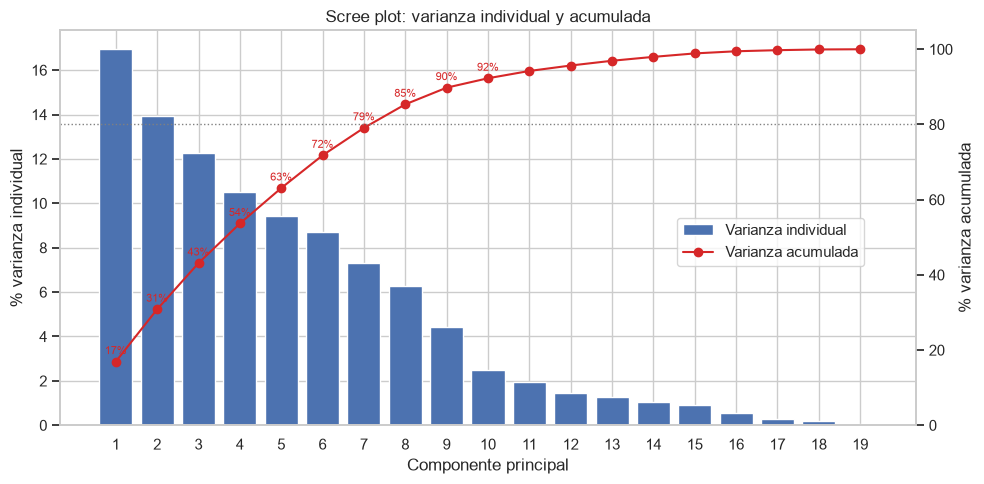

,varianza_%,acumulada_%
PC1,16.940,16.940
PC2,13.917,30.857
PC3,12.275,43.133
PC4,10.529,53.662
PC5,9.422,63.084
PC6,8.706,71.790
PC7,7.306,79.096
PC8,6.255,85.352
PC9,4.436,89.787
PC10,2.504,92.291


In [3]:
variance = pd.DataFrame({
    "varianza_%": pca.explained_variance_ratio_ * 100,
    "acumulada_%": pca.explained_variance_ratio_.cumsum() * 100,
}, index=PCS)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(range(1, len(PCS) + 1), variance["varianza_%"], label="Varianza individual")
ax1.set(xlabel="Componente principal", ylabel="% varianza individual", xticks=range(1, len(PCS) + 1))

ax2 = ax1.twinx()
ax2.plot(range(1, len(PCS) + 1), variance["acumulada_%"], color="tab:red", marker="o", label="Varianza acumulada")
ax2.axhline(80, color="gray", linestyle=":", linewidth=1)
ax2.set(ylabel="% varianza acumulada", ylim=(0, 105))
ax2.grid(False)
for i, v in enumerate(variance["acumulada_%"]):
    if i < 10:
        ax2.text(i + 1, v + 2, f"{v:.0f}%", ha="center", fontsize=8, color="tab:red")

ax1.set_title("Scree plot: varianza individual y acumulada")
fig.legend(loc="center right", bbox_to_anchor=(0.88, 0.5))
plt.tight_layout()
plt.show()

variance.head(10)

**Interpretación**

- La varianza está **muy repartida**: PC1 explica el 16,9 %, PC2 el 13,9 % y PC3 el 12,3 %. No hay una o dos componentes dominantes.
- Las dos primeras componentes recogen solo el **30,9 %** de la información y las tres primeras el **43,1 %**. Hacen falta **8 componentes para llegar al 80 %** y 10 para el 90 %.
- Consecuencia directa para la visualización: un scatter 2D muestra menos de un tercio de la estructura de los datos. Si los clusters se solapan en 2D, **no significa** que estén mal formados en las 19 dimensiones: puede que lo que los separa esté en componentes que no se dibujan (ver sección 5).
- Las últimas componentes (PC15–PC19) explican menos del 1 % cada una: corresponden a binarias poco frecuentes (B2B, categorías raras de financiación).

## 3. Variables que más pesan en cada componente (loadings)

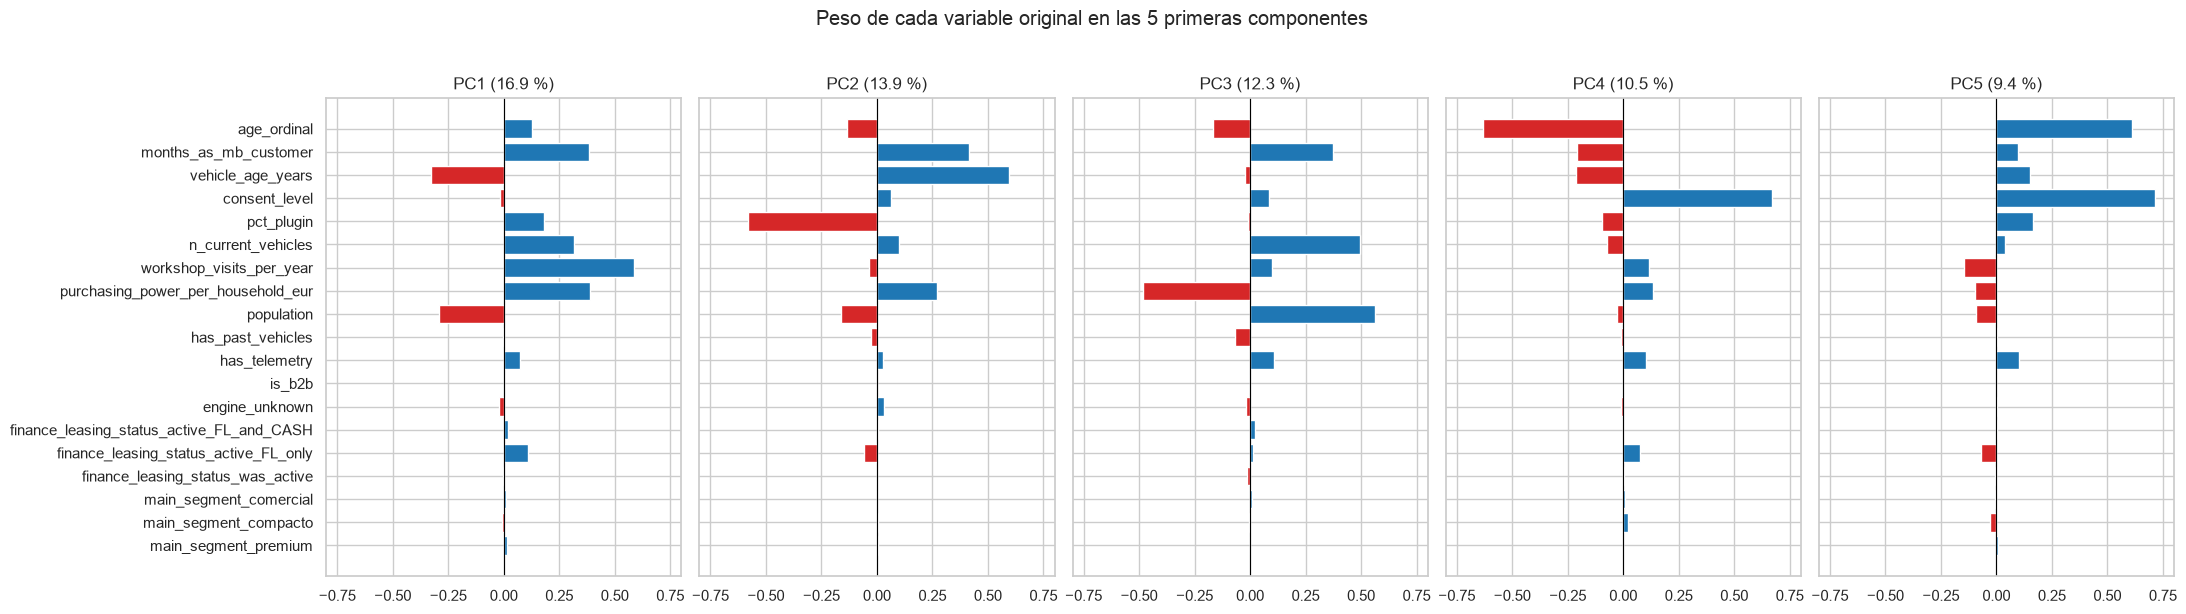

In [4]:
loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=PCS)

N_SHOW = 5
fig, axes = plt.subplots(1, N_SHOW, figsize=(22, 6), sharey=True)
for ax, pc in zip(axes, PCS[:N_SHOW]):
    values = loadings[pc]
    ax.barh(values.index, values, color=np.where(values >= 0, "tab:blue", "tab:red"))
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set(title=f"{pc} ({variance.loc[pc, 'varianza_%']:.1f} %)", xlim=(-0.8, 0.8))
axes[0].invert_yaxis()
plt.suptitle("Peso de cada variable original en las 5 primeras componentes", y=1.02)
plt.tight_layout()
plt.show()

In [5]:
def top_loadings(pc, n=4):
    top = loadings[pc].abs().sort_values(ascending=False).head(n).index
    return ", ".join(f"{name} ({loadings.loc[name, pc]:+.2f})" for name in top)

pd.DataFrame({
    "varianza_%": variance["varianza_%"].head(N_SHOW).round(1),
    "variables con más peso": [top_loadings(pc) for pc in PCS[:N_SHOW]],
})

,varianza_%,variables con más peso
PC1,16.900,"workshop_visits_per_year (+0.59), purchasing_power_per_household_eur (+0.39), months_as_mb_customer (+0.39), vehicle_age_years (-0.33)"
PC2,13.900,"vehicle_age_years (+0.60), pct_plugin (-0.58), months_as_mb_customer (+0.41), purchasing_power_per_household_eur (+0.27)"
PC3,12.300,"population (+0.56), n_current_vehicles (+0.49), purchasing_power_per_household_eur (-0.48), months_as_mb_customer (+0.37)"
PC4,10.500,"consent_level (+0.67), age_ordinal (-0.63), vehicle_age_years (-0.21), months_as_mb_customer (-0.21)"
PC5,9.400,"consent_level (+0.72), age_ordinal (+0.61), pct_plugin (+0.17), vehicle_age_years (+0.15)"


**Interpretación de las componentes principales**

El signo de cada carga indica la dirección: un cliente con valor alto en la componente tiene valores altos en las variables con carga positiva y bajos en las de carga negativa.

| Componente | Variables con más peso | Interpretación de negocio |
|---|---|---|
| **PC1** (16,9 %) | visitas de garantía/año (+0,59), poder adquisitivo (+0,39), antigüedad como cliente (+0,39), edad del vehículo (−0,33), nº de vehículos (+0,32) | **Intensidad de la relación con la marca**: valores altos = cliente antiguo, con más vehículos, coche reciente que pasa por el taller y en zona acomodada |
| **PC2** (13,9 %) | edad del vehículo (+0,60), % enchufables (−0,58), antigüedad (+0,41) | **Coche veterano de combustión ↔ coche nuevo electrificado** |
| **PC3** (12,3 %) | población (+0,56), nº de vehículos (+0,49), poder adquisitivo (−0,48) | **Entorno**: zona urbana y con varios vehículos frente a zona acomodada menos poblada |
| **PC4 y PC5** (10,5 % y 9,4 %) | nivel de consentimiento (+0,67 / +0,72) y edad del cliente (−0,63 / +0,61) | **Contactabilidad** del cliente, combinada con su edad |

- Las binarias y one-hot apenas aparecen en las primeras componentes, como se esperaba por su menor varianza (sección 1).
- Las tres primeras componentes recogen justo los ejes que definen a **Fieles Acomodados** (PC1 alto), **Pioneros Eléctricos** (PC2 bajo) y **Candidatos a Renovación** (PC1 bajo, PC2 alto). El consentimiento, que define a los **Clientes Silenciosos**, no aparece hasta PC4–PC5.

## 4. Scatter 2D y 3D coloreado por segmento

Con 173.454 puntos los colores se taparían unos a otros y el gráfico mostraría sobre todo el último cluster dibujado. Se dibuja una **muestra aleatoria de 15.000 clientes**, suficiente para ver la forma de la nube. Los centroides de cada segmento se calculan con **todos** los clientes.

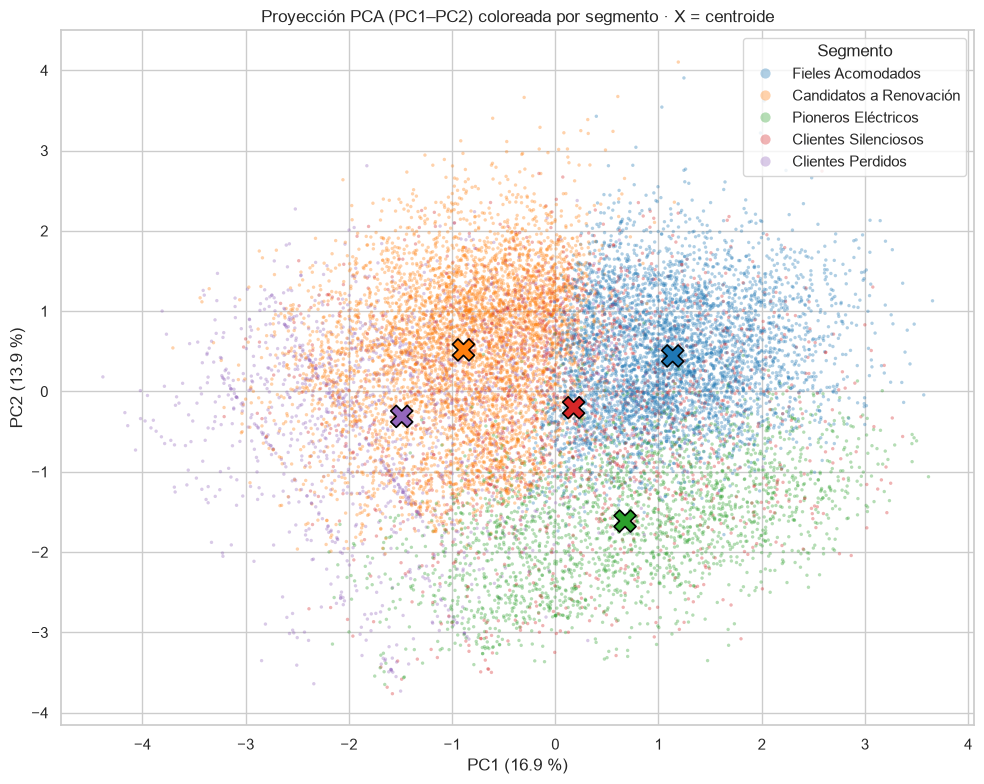

,PC1,PC2,PC3,PC4,PC5
Fieles Acomodados,1.140,0.440,0.120,0.420,0.050
Candidatos a Renovación,-0.890,0.520,0.320,0.200,0.270
Pioneros Eléctricos,0.680,-1.610,0.180,0.070,0.590
Clientes Silenciosos,0.180,-0.200,-0.080,-1.710,-1.560
Clientes Perdidos,-1.490,-0.310,-1.600,0.180,-0.010


In [6]:
rng = np.random.default_rng(42)
sample = rng.choice(len(Z), 15_000, replace=False)
plot_df = Z.iloc[sample, :5].assign(segmento=segment[sample])
centroids = Z.iloc[:, :5].groupby(segment, observed=True).mean()

def scatter(ax, x, y):
    sns.scatterplot(data=plot_df, x=x, y=y, hue="segmento", palette=PALETTE, s=6, alpha=0.35, linewidth=0, ax=ax)
    ax.scatter(centroids[x], centroids[y], c=[PALETTE[s] for s in centroids.index], s=250, marker="X", edgecolor="black", linewidth=1.2)
    ax.set(xlabel=f"{x} ({variance.loc[x, 'varianza_%']:.1f} %)", ylabel=f"{y} ({variance.loc[y, 'varianza_%']:.1f} %)")

fig, ax = plt.subplots(figsize=(10, 8))
scatter(ax, "PC1", "PC2")
ax.set_title("Proyección PCA (PC1–PC2) coloreada por segmento · X = centroide")
ax.legend(title="Segmento", markerscale=3, loc="upper right")
plt.tight_layout()
plt.show()

centroids.round(2)

Para ver si cada segmento ocupa una zona propia, se dibuja cada uno por separado sobre la nube completa (en gris):

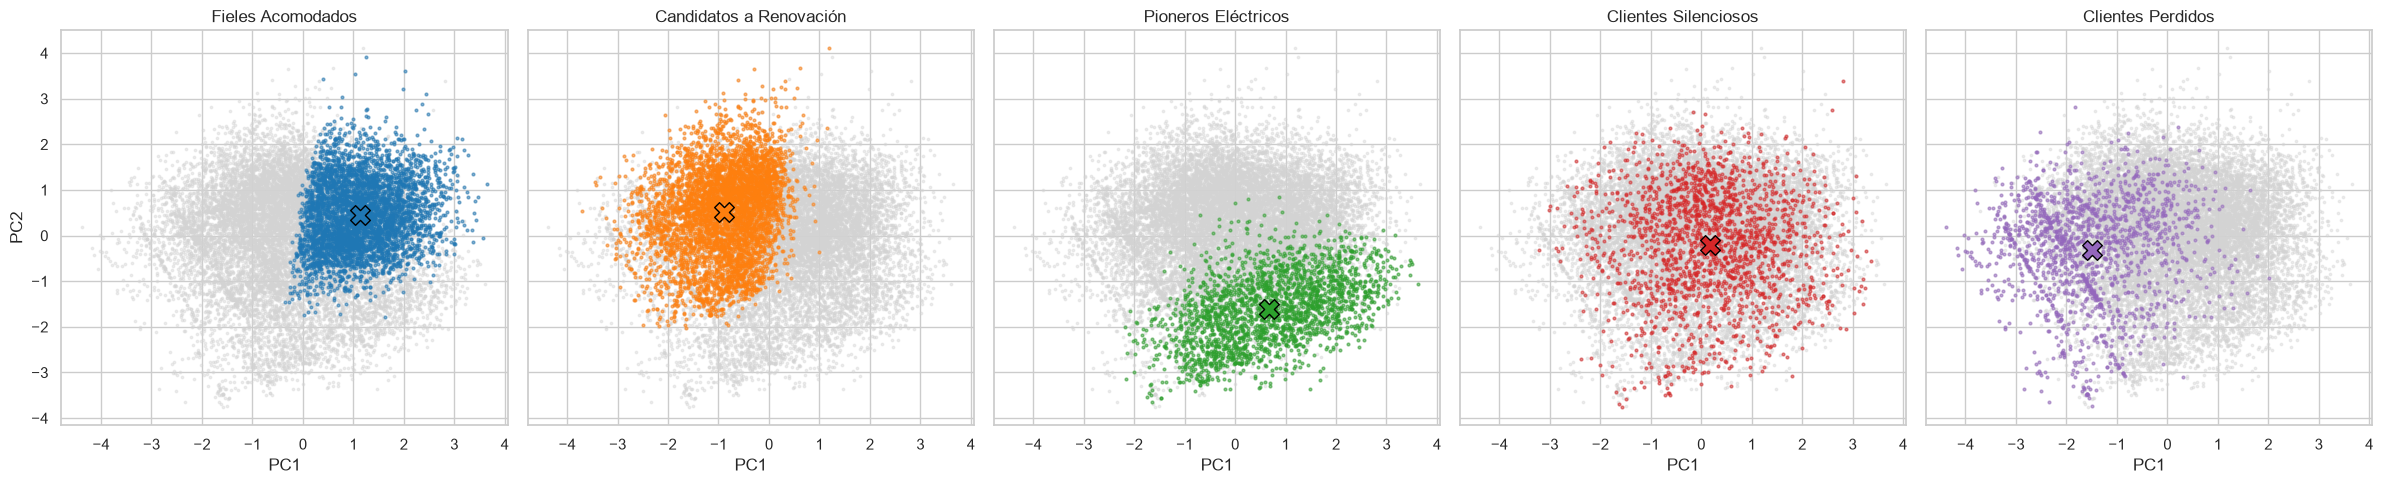

In [7]:
fig, axes = plt.subplots(1, len(ORDER), figsize=(24, 5), sharex=True, sharey=True)
for ax, name in zip(axes, ORDER):
    ax.scatter(plot_df["PC1"], plot_df["PC2"], s=3, color="lightgray", alpha=0.4)
    own = plot_df[plot_df["segmento"] == name]
    ax.scatter(own["PC1"], own["PC2"], s=4, color=PALETTE[name], alpha=0.5)
    ax.scatter(centroids.loc[name, "PC1"], centroids.loc[name, "PC2"], s=200, marker="X", color=PALETTE[name], edgecolor="black")
    ax.set(title=name, xlabel="PC1")
axes[0].set_ylabel("PC2")
plt.tight_layout()
plt.show()

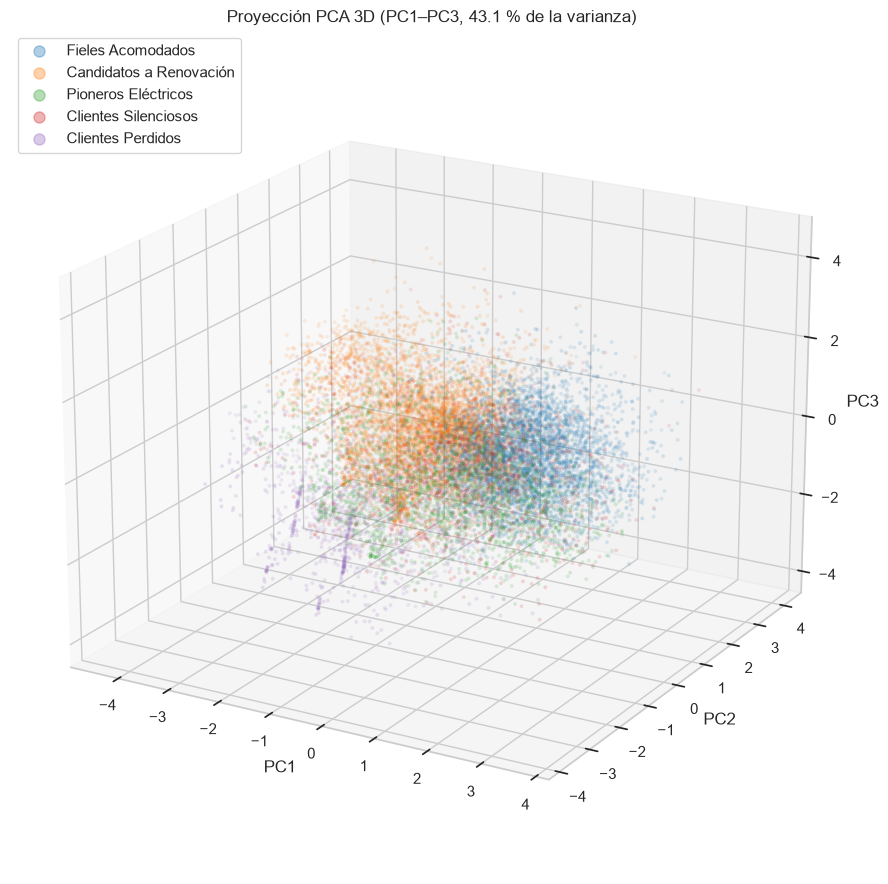

In [8]:
fig = plt.figure(figsize=(11, 9))
ax = fig.add_subplot(projection="3d")
for name in ORDER:
    part = plot_df[plot_df["segmento"] == name]
    ax.scatter(part["PC1"], part["PC2"], part["PC3"], s=4, alpha=0.35, color=PALETTE[name], label=name)
ax.set(xlabel="PC1", ylabel="PC2", zlabel="PC3",
       title=f"Proyección PCA 3D (PC1–PC3, {variance.loc['PC3', 'acumulada_%']:.1f} % de la varianza)")
ax.view_init(elev=20, azim=-60)
ax.legend(markerscale=4, loc="upper left")
plt.tight_layout()
plt.show()

**Interpretación**

- **En PC1–PC2 se distinguen tres segmentos**, cada uno en una zona de la nube que coincide con la interpretación de las componentes:
  - **Pioneros Eléctricos**: abajo (PC2 bajo = coche nuevo y enchufable).
  - **Fieles Acomodados**: a la derecha (PC1 alto = relación intensa con la marca).
  - **Candidatos a Renovación**: a la izquierda y arriba (PC1 bajo, PC2 alto = coche veterano de combustión).
- Aun así, **las nubes se tocan y se solapan en los bordes**: no hay huecos vacíos entre segmentos. Encaja con el Silhouette bajo del Reto 3 (~0,14): los clientes forman un continuo y los segmentos lo parten en zonas.
- **Clientes Perdidos** queda en 2D en el extremo izquierdo (PC1 bajo), mezclado con Candidatos a Renovación; se separa mejor en el **3D**, por PC3 bajo (sin vehículos actuales), donde su centroide (−1,6) es el más alejado del resto.
- **Clientes Silenciosos** queda **en el centro** de la nube en PC1–PC3 (centroide próximo a 0 en las tres): con estas componentes no se distingue. Se analiza en la sección siguiente.

## 5. ¿Dónde están los Clientes Silenciosos?

Según los loadings, el nivel de consentimiento, la variable que define a este segmento, pesa sobre todo en **PC4 y PC5**. Se proyecta la nube sobre esas dos componentes:

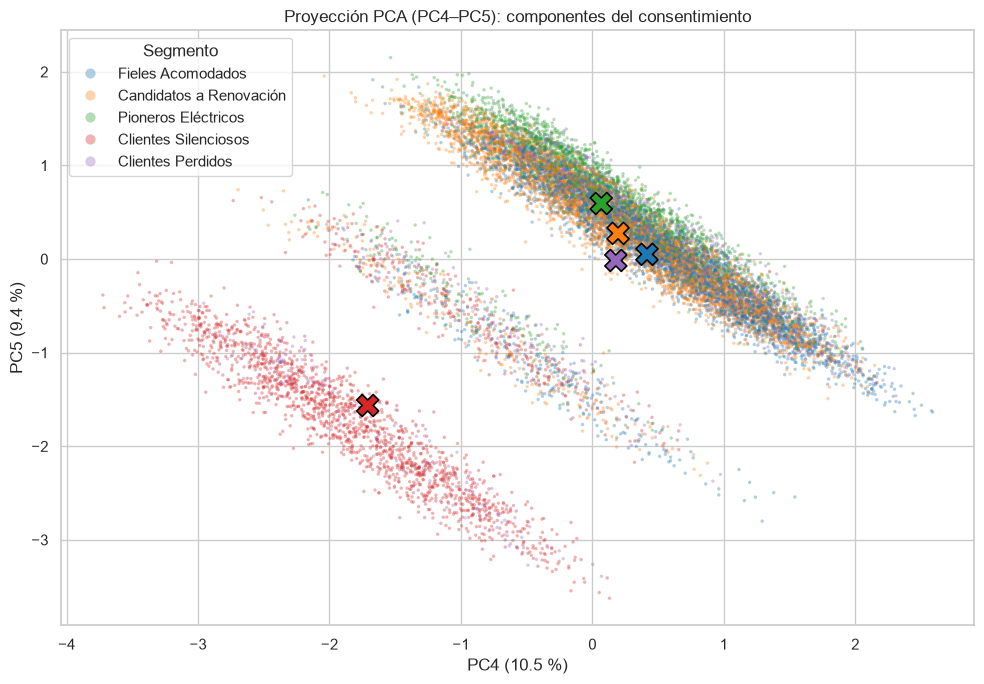

In [9]:
fig, ax = plt.subplots(figsize=(10, 7))
scatter(ax, "PC4", "PC5")
ax.set_title("Proyección PCA (PC4–PC5): componentes del consentimiento")
ax.legend(title="Segmento", markerscale=3, loc="upper left")
plt.tight_layout()
plt.show()

**Interpretación**

- La nube forma **tres bandas paralelas**: corresponden a los niveles de `consent_level` (3, 2 o 1 canal de comunicación aceptado), porque es una variable con solo unos pocos valores posibles.
- La banda inferior (un único canal, casi siempre ePost) es prácticamente toda de **Clientes Silenciosos**, que se separan con claridad del resto (centroide en −1,7 en PC4 y −1,6 en PC5, frente a valores cercanos a 0 en los demás). La banda intermedia (2 canales) mezcla varios segmentos.
- Es la demostración de lo que anticipaba la varianza explicada: un segmento puede estar **bien definido en las 19 dimensiones y ser invisible en el scatter 2D**, porque lo que lo distingue no está en las dos primeras componentes.

## 6. Valoración: ¿los clusters son visualmente separables?

Para apoyar la valoración visual con una cifra, se calcula el Silhouette de los **mismos clusters** (no se reentrena nada) midiendo las distancias en distintos espacios, sobre una muestra de 20.000 clientes:

In [10]:
idx = np.random.default_rng(42).choice(len(X), 20_000, replace=False)
spaces = {
    "PCA 2D (PC1–PC2)": Z.iloc[idx, :2],
    "PCA 3D (PC1–PC3)": Z.iloc[idx, :3],
    "PCA 5D (PC1–PC5)": Z.iloc[idx, :5],
    "19 features originales": X.iloc[idx],
}
separability = pd.DataFrame({
    "varianza_explicada_%": [variance["acumulada_%"].iloc[1], variance["acumulada_%"].iloc[2], variance["acumulada_%"].iloc[4], 100],
    "silhouette": [silhouette_score(data, clusters.iloc[idx]) for data in spaces.values()],
}, index=list(spaces))
separability

,varianza_explicada_%,silhouette
PCA 2D (PC1–PC2),30.857,0.126
PCA 3D (PC1–PC3),43.133,0.138
PCA 5D (PC1–PC5),63.084,0.164
19 features originales,100.000,0.137


**Valoración**

**Los clusters son parcialmente separables a simple vista**, y el grado de separación depende del segmento:

| Segmento | ¿Separable? | Dónde se ve |
|---|---|---|
| Pioneros Eléctricos | **Sí** | PC2 (coche nuevo y enchufable) |
| Fieles Acomodados | **Sí**, con solape en el borde | PC1 (relación intensa con la marca) |
| Candidatos a Renovación | **Sí**, con solape en el borde | PC1 bajo + PC2 alto |
| Clientes Perdidos | **Parcialmente** | En 3D, por PC3 |
| Clientes Silenciosos | **No en 2D/3D** | Solo en PC4–PC5 (consentimiento) |

- No hay fronteras limpias: las nubes forman un continuo y los segmentos son **zonas** de ese continuo, no grupos aislados. Lo confirma el Silhouette, que es bajo en cualquier espacio.
- El Silhouette en 2D (0,126) y en 3D (0,138) es parecido al de las 19 dimensiones (0,137). En 5D sube a 0,164 porque ahí entran las componentes del consentimiento (que separan a los Silenciosos) y se descarta el ruido de las últimas componentes. Aun así, **la proyección no "mejora" los clusters**: son exactamente los mismos, solo cambia el espacio en que se miden las distancias, y comparar Silhouettes de espacios distintos no indica un mejor clustering.
- **Conclusión:** la visualización PCA **confirma la interpretación de negocio del Reto 4** (cada segmento cae en la zona que predicen sus rasgos) y explica por qué el Silhouette es moderado: la segmentación es útil y coherente, pero los clientes no forman grupos naturalmente aislados.